<a href="https://colab.research.google.com/github/M9249/Function.py/blob/main/Applying_Kernel_Mask.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Image Filtering using Kernels (Masks)
This notebook demonstrates how to apply three spatial filtering operations on an image using custom and standard kernels:
1. **Sharpening** (using a Laplacian/high-pass filter kernel)
2. **Blur** (using a Gaussian kernel)
3. **Averaging** (using a box filter/mean kernel)
```

```markdown
## Step 1: Mount Google Drive
Run this cell to mount your Google Drive to the `/content/drive` path.
```

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

Mounted at /content/drive


```markdown
## Step 2: Search for the Image in Google Drive
This script searches your Google Drive to locate the exact path of your image containing 'WhatsApp' and '9.52.28' in its filename.
```

In [ ]:
import glob

# Search recursively in Google Drive
search_pattern = "/content/drive/MyDrive/**/*WhatsApp*9.52.28*.jpeg"
found_files = glob.glob(search_pattern, recursive=True)

# Fallback to general WhatsApp images if the exact timestamp is slightly different
if not found_files:
    search_pattern = "/content/drive/MyDrive/**/*WhatsApp*.jp*g"
    found_files = glob.glob(search_pattern, recursive=True)

if found_files:
    print("Found matching images in your Google Drive:")
    for i, filepath in enumerate(found_files):
        print(f"[{i}]: {filepath}")
    # Select the first match by default
    drive_image_path = found_files[0]
    print(f"\nSelected Path: {drive_image_path}")
else:
    print("Could not find any matching WhatsApp JPEG images in your Google Drive.")
    print("Please make sure you uploaded the image to your Google Drive first.")

Found matching images in your Google Drive:
[0]: /content/drive/MyDrive/WhatsApp Image 2026-09-25 at 9.52.28 AMq.jpeg

Selected Path: /content/drive/MyDrive/WhatsApp Image 2026-09-25 at 9.52.28 AMq.jpeg


```markdown
## Step 3: Load the Selected Image from Drive
Now we will load the detected Google Drive image.
```

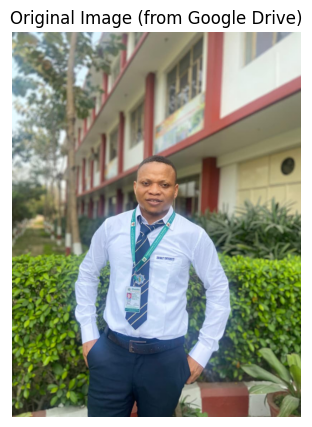

In [ ]:
if 'drive_image_path' in locals() and os.path.exists(drive_image_path):
    img = cv2.imread(drive_image_path, cv2.IMREAD_COLOR)
    if img is not None:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(5, 5))
        plt.imshow(img_rgb)
        plt.title('Original Image (from Google Drive)')
        plt.axis('off')
        plt.show()
    else:
        print("Failed to decode the image file.")
else:
    print("Please mount your drive and verify the file exists.")

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Path of the uploaded image inside Colab's default working directory
image_path = '/content/WhatsApp Image 2026-09-25 at 9.52.28 AMq.jpeg'

if os.path.exists(image_path):
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    # Convert color space from BGR to RGB for matplotlib
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Display original image
    plt.figure(figsize=(5, 5))
    plt.imshow(img_rgb)
    plt.title('Original Image')
    plt.axis('off')
    plt.show()
else:
    print(f"Error: '{os.path.basename(image_path)}' not found in /content/.")
    print("Please upload the image via the files explorer sidebar on the left and run this cell again.")

Error: 'WhatsApp Image 2026-09-25 at 9.52.28 AMq.jpeg' not found in /content/.
Please upload the image via the files explorer sidebar on the left and run this cell again.


```markdown
## Applying Kernels / Masks
We will define the filters and apply them using `cv2.filter2D`.
```

In [ ]:
# Use the loaded image from your Google Drive (img_rgb)
# --- 1. Sharpening Kernel ---
sharpen_kernel = np.array([[
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
]], dtype=np.float32).reshape(3, 3)

img_sharpened = cv2.filter2D(img_rgb, -1, sharpen_kernel)

# --- 2. Blur (Gaussian Blur) Kernel ---
gaussian_kernel = np.array([
    [1,  4,  6,  4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1,  4,  6,  4, 1]
], dtype=np.float32) / 256.0

img_blurred = cv2.filter2D(img_rgb, -1, gaussian_kernel)

# --- 3. Averaging (Box Filter) Kernel ---
kernel_size = 5
averaging_kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)

img_averaged = cv2.filter2D(img_rgb, -1, averaging_kernel)

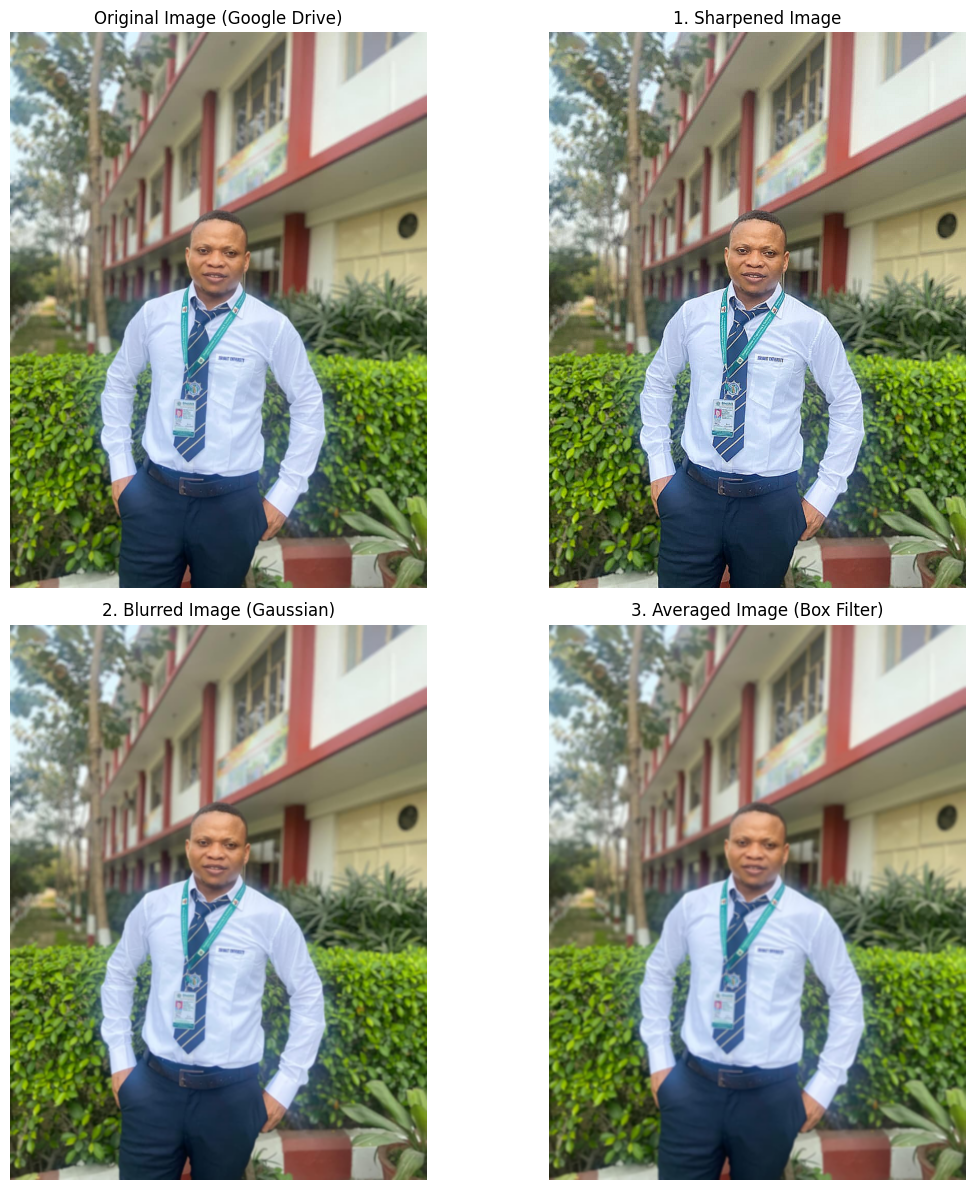

In [ ]:
# --- Visualization of Google Drive Image Operations ---
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# Original from Drive
axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title('Original Image (Google Drive)')
axes[0, 0].axis('off')

# 1. Sharpening
axes[0, 1].imshow(img_sharpened)
axes[0, 1].set_title('1. Sharpened Image')
axes[0, 1].axis('off')

# 2. Blur (Gaussian)
axes[1, 0].imshow(img_blurred)
axes[1, 0].set_title('2. Blurred Image (Gaussian)')
axes[1, 0].axis('off')

# 3. Averaging
axes[1, 1].imshow(img_averaged)
axes[1, 1].set_title('3. Averaged Image (Box Filter)')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()